Tasks 6, 7, 8 and 9: Develop the ShowerEnv Class

GOAL: To adjust flow_rate_hot to obtain the desired outlet temp of 35 degree celcius

Variable: Turning Angle </br>
Range: [-100, +100]

Within each trainnig episode:
1. Evironment provide current state
2. Agent take step and choose action
3. Environment perform action
4. Agent receive the rewards and update q-value 

After each episode done:
1. reset

In [2]:
import gymnasium as gym
import numpy as np
from matplotlib import pyplot as plt

In [3]:
class ShowerEnv(gym.Env):
    def __init__(self, Thot, Tcold, max_angle_change, Tdesired):
        self.Thot = Thot
        self.Tcold = Tcold
        self.cold_flow_rate = 50
        self.max_angle_change = max_angle_change
        self.Tdesired = Tdesired

    def reset(self):
        self.angle_hot = 20
        self.state = (self.angle_hot *self.Thot + self.cold_flow_rate * self.Tcold) / (self.angle_hot + self.cold_flow_rate)

        return np.array([self.state])

    def step(self, action):

        angle_change = (action - 10) * 10
        self.angle_hot = np.clip(self.angle_hot + angle_change, 0, 100)
        self.state = (self.angle_hot * self.Thot + self.cold_flow_rate * self.Tcold) / (self.angle_hot + self.cold_flow_rate)

        error = 3
        if abs(self.state - self.Tdesired) <= error:
            reward = 10
        elif abs(self.state - self.Tdesired) <= error*2:
            reward = -1
        elif abs(self.state - self.Tdesired) <= error*3:
            reward = -5
        else:
            reward = -10

        done = True if abs(self.state - self.Tdesired) <= (1.5 * error) else False
        

        return np.array([self.state]), reward, done

    

Task 10: Train the Agent

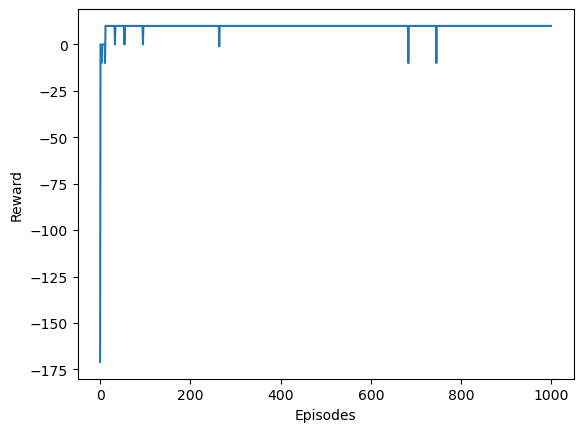

In [6]:
from Agent2 import Agent2

if __name__ == "__main__":
    env = ShowerEnv(Thot=100, Tcold=5, max_angle_change=10, Tdesired=35)
    agent = Agent2(lr=0.01, gamma=0.995, n_actions=21, eps_dec=0.9, eps_start=1.0, eps_end=0.01)

    n_episodes = 1000

    scores = []

    for episode in range(n_episodes):
        state = env.reset()
        done = False
        score = 0

        while not done:
            action = agent.choose_actions(state)
            next_state, reward, done = env.step(action)
            agent.learn(state, action, reward, next_state)
            state = next_state
            score += reward

        scores.append(score)

    # The plot: The learning curve of the agent's performance over episodes, showing how the total reward changes as the agent learns.
    plt.plot(scores)     
    plt.xlabel('Episodes')
    plt.ylabel('Reward')
    